# CLASP and IMSTE on a selected single-cell dataset

Choose a dataset, an optional number of top differentially expressed genes, a number of PCA features, and a neighborhood visualization. The notebook builds a CLASP integration graph when multiple batches are present, or a within-batch kNN graph for single-batch data. It compares graph-based UMAP and IMSTE embeddings with label scatter plots and either kNN neighborhood unions or density-parent trees, plus an interactive label-guided adjustment.

In [1]:
%config InlineBackend.figure_format = 'retina'
%load_ext autoreload
%autoreload 2

from pathlib import Path
import importlib.util
import inspect
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

REPO_ROOT = next(
    (parent for parent in (Path.cwd(), *Path.cwd().parents)
     if (parent / "src" / "clasp").is_dir()),
    None,
)
if REPO_ROOT is None:
    raise RuntimeError("Could not find the CLASP project root from the notebook working directory")
NOTEBOOK_DIR = REPO_ROOT / "notebooks"
for import_path in (REPO_ROOT / "src", NOTEBOOK_DIR):
    if str(import_path) not in sys.path:
        sys.path.insert(0, str(import_path))

import imste_single_cell
import clasp_imste_workflow as workflow

IMSTE_EMBEDDER_CLASS = imste_single_cell.load_embedder_class()
IMSTE_VISUALIZATION_PATH = Path(inspect.getfile(IMSTE_EMBEDDER_CLASS)).parent / "visualization.py"
if not IMSTE_VISUALIZATION_PATH.is_file():
    raise FileNotFoundError(f"IMSTE visualization utilities not found: {IMSTE_VISUALIZATION_PATH}")
_visualization_spec = importlib.util.spec_from_file_location(
    "imste_visualization_tools", IMSTE_VISUALIZATION_PATH
)
imste_visualization = importlib.util.module_from_spec(_visualization_spec)
_visualization_spec.loader.exec_module(imste_visualization)
plot_embedding = imste_single_cell.plot_embedding
plot_density_parent_tree = imste_single_cell.plot_density_parent_tree
plot_knn_union = imste_visualization.plot_knn_union
interactive_force = imste_visualization.interactive_force


In [2]:
import ipywidgets as widgets

AVAILABLE_DATASETS = imste_single_cell.available_datasets()
DEFAULT_DATASET_NAME = "human_pancreas_norm_complexBatch.h5ad"
DEFAULT_DATASET = next(
    (path for path in AVAILABLE_DATASETS if path.name == DEFAULT_DATASET_NAME),
    AVAILABLE_DATASETS[0],
)
DATASET_SELECTOR = widgets.Dropdown(
    options=[(path.name, str(path.resolve())) for path in AVAILABLE_DATASETS],
    value=str(DEFAULT_DATASET.resolve()),
    description="Dataset:",
    layout=widgets.Layout(width="80%"),
)
N_TOP_GENES_SELECTOR = widgets.Dropdown(
    options=[("All genes", None), ("Top 500 DE genes", 500),
             ("Top 1,000 DE genes", 1_000), ("Top 2,000 DE genes", 2_000)],
    value=None,
    description="Top genes:",
)
PC_COUNT_SELECTOR = widgets.Dropdown(
    options=[("20 PCs", 20), ("30 PCs", 30), ("50 PCs", 50),
             ("75 PCs", 75), ("100 PCs", 100)],
    value=50,
    description="PCs:",
)
MAX_CELLS_SELECTOR = widgets.Dropdown(
    options=[("2,000 cells", 2_000), ("4,000 cells", 4_000),
             ("10,000 cells", 10_000), ("All available", None)],
    value=4_000,
    description="Cells:",
)
NEIGHBORHOOD_VIEW_SELECTOR = widgets.Dropdown(
    options=[("Density-parent tree", "density"), ("kNN neighborhood union", "knn")],
    value="density",
    description="Overlay:",
)
RANDOM_STATE = 42
display(DATASET_SELECTOR, N_TOP_GENES_SELECTOR, PC_COUNT_SELECTOR,
        MAX_CELLS_SELECTOR, NEIGHBORHOOD_VIEW_SELECTOR)


Dropdown(description='Dataset:', index=9, layout=Layout(width='80%'), options=(('Immune_ALL_hum_mou.h5ad', '/U…

Dropdown(description='Top genes:', options=(('All genes', None), ('Top 500 DE genes', 500), ('Top 1,000 DE gen…

Dropdown(description='PCs:', index=2, options=(('20 PCs', 20), ('30 PCs', 30), ('50 PCs', 50), ('75 PCs', 75),…

Dropdown(description='Cells:', index=1, options=(('2,000 cells', 2000), ('4,000 cells', 4000), ('10,000 cells'…

Dropdown(description='Overlay:', options=(('Density-parent tree', 'density'), ('kNN neighborhood union', 'knn'…

In [3]:
# CLASP preprocessing and graph-construction parameters.
CLASP_PREPROCESS_PARAMS = {
    "n_top_genes": None,  # The selector above performs DE selection before this step.
    "max_cells": None,
    "min_cell_genes": None,
    "min_gene_counts": 0,
    "normalize": "auto",
    "target_sum": 10_000,
    "log1p": True,
}
CLASP_PARAMS = {
    "pca_components": 50,  # Updated from PC_COUNT_SELECTOR before fitting.
    "n_neighbors": 15,
    "intra_fraction": 0.5,
    "n_inter_edges": 1,
    "metric": "euclidean",
    "assignment_quantile": 0.95,
    "hubness_correction": "csls",
    "hubness_k": 10,
    "rank_correction": True,
    "edge_weighting": "distance",
    "inter_edge_mode": "propagate_neighbors",
    "mutual_neighbors": True,
    "neighbor_mode": "distance",
    "symmetrize": True,
}
UMAP_PARAMS = {
    "n_neighbors": 30,
    "min_dist": 0.3,
    "n_epochs": 500,
    "low_memory": True,
}
IMSTE_PARAMS = {
    "n_msts": 16,
    "n_components": 2,
    "n_epochs": 2000,
    "batch_size": 32_768,
    "learning_rate": 0.05,
    "negative_ratio": 1,
    "lambda_rep": 0.5,
    "random_state": RANDOM_STATE,
    "epsilon": 1e-4,
    "device": "auto",
    "logistic_margin": 1.5,
    "logistic_temperature": 0.5,
    "mst_method": "famst",
    "mst_neighbors": 15,
    "mst_inter_component_edges": 5,
    "mst_max_neighbors": 512,
    "mst_representatives_per_component": 10,
    "pca_init": True,
    "pca_init_scaling": "global",
    "progress_callback": None,
    "mst_progress_callback": None,
}
display(pd.DataFrame({"CLASP": pd.Series(CLASP_PARAMS), "UMAP": pd.Series(UMAP_PARAMS)}))
display(pd.Series(IMSTE_PARAMS, name="IMSTE").to_frame())


,CLASP,UMAP
assignment_quantile,0.95,NaN
edge_weighting,distance,NaN
hubness_correction,csls,NaN
hubness_k,10,NaN
inter_edge_mode,propagate_neighbors,NaN
intra_fraction,0.5,NaN
low_memory,NaN,True
metric,euclidean,NaN
min_dist,NaN,0.3
mutual_neighbors,True,NaN


,IMSTE
n_msts,16
n_components,2
n_epochs,2000
batch_size,32768
learning_rate,0.05
negative_ratio,1
lambda_rep,0.5
random_state,42
epsilon,0.0001
device,auto


In [4]:
DATASET_PATH = Path(DATASET_SELECTOR.value).resolve()
N_TOP_GENES = N_TOP_GENES_SELECTOR.value
N_PCS = PC_COUNT_SELECTOR.value
MAX_CELLS = MAX_CELLS_SELECTOR.value
CLASP_PARAMS["pca_components"] = N_PCS
X, obs, row_indices = imste_single_cell.load_dataset(
    path=DATASET_PATH,
    matrix_key="X",
    obs_keys=tuple(imste_single_cell.available_obs_columns(DATASET_PATH)),
    max_cells=MAX_CELLS,
    random_state=RANDOM_STATE,
)
LABEL_KEY = imste_single_cell.default_label_key(obs)
obs = obs.copy()
BATCH_KEY = workflow.infer_batch_key(obs)
X, selected_gene_indices = workflow.select_top_de_genes(
    X, obs, LABEL_KEY, N_TOP_GENES
)

label_categories = pd.Categorical(obs[LABEL_KEY]).categories
label_cmap = plt.get_cmap("tab20", max(len(label_categories), 1))
# Match plot_knn_union, which assigns tab20 colors in categorical order.
LABEL_COLORS = {
    str(label): label_cmap(index)
    for index, label in enumerate(label_categories)
}
if obs[LABEL_KEY].isna().any():
    LABEL_COLORS["Missing"] = (0.5, 0.5, 0.5, 1.0)

print(f"Dataset: {DATASET_PATH.name}")
print(f"PCA features requested: {N_PCS}")
print(f"Cells: {len(obs):,}; genes used: {X.shape[1]:,}")
print(f"Rows loaded: {len(row_indices):,} (cell limit: {MAX_CELLS if MAX_CELLS is not None else 'all'}); label: {LABEL_KEY}; batch: {BATCH_KEY}")
if N_TOP_GENES is None:
    print("Differential-expression gene selection: skipped")
else:
    print(f"Selected {X.shape[1]:,} top DE genes (requested {N_TOP_GENES:,})")


Dataset: human_pancreas_norm_complexBatch.h5ad
PCA features requested: 50
Cells: 4,000; genes used: 1,000
Rows loaded: 4,000 (cell limit: 4000); label: celltype; batch: tech
Selected 1,000 top DE genes (requested 1,000)


In [5]:
processed_adata, clasp_graph, umap_embedding, imste_embedding, clasp_estimator = (
    workflow.fit_clasp_umap_imste(
        X,
        obs,
        label_key=LABEL_KEY,
        batch_key=BATCH_KEY,
        clasp_params=CLASP_PARAMS,
        preprocess_params=CLASP_PREPROCESS_PARAMS,
        umap_params=UMAP_PARAMS,
        imste_params=IMSTE_PARAMS,
        random_state=RANDOM_STATE,
        imste_embedder_class=IMSTE_EMBEDDER_CLASS,
    )
)
print(f"CLASP graph: {clasp_graph.shape}; {clasp_graph.nnz:,} directed nonzero entries")
print(f"UMAP embedding: {umap_embedding.shape}; IMSTE embedding: {imste_embedding.shape}")


/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)


CLASP graph: (4000, 4000); 304,984 directed nonzero entries
UMAP embedding: (4000, 2); IMSTE embedding: (4000, 2)


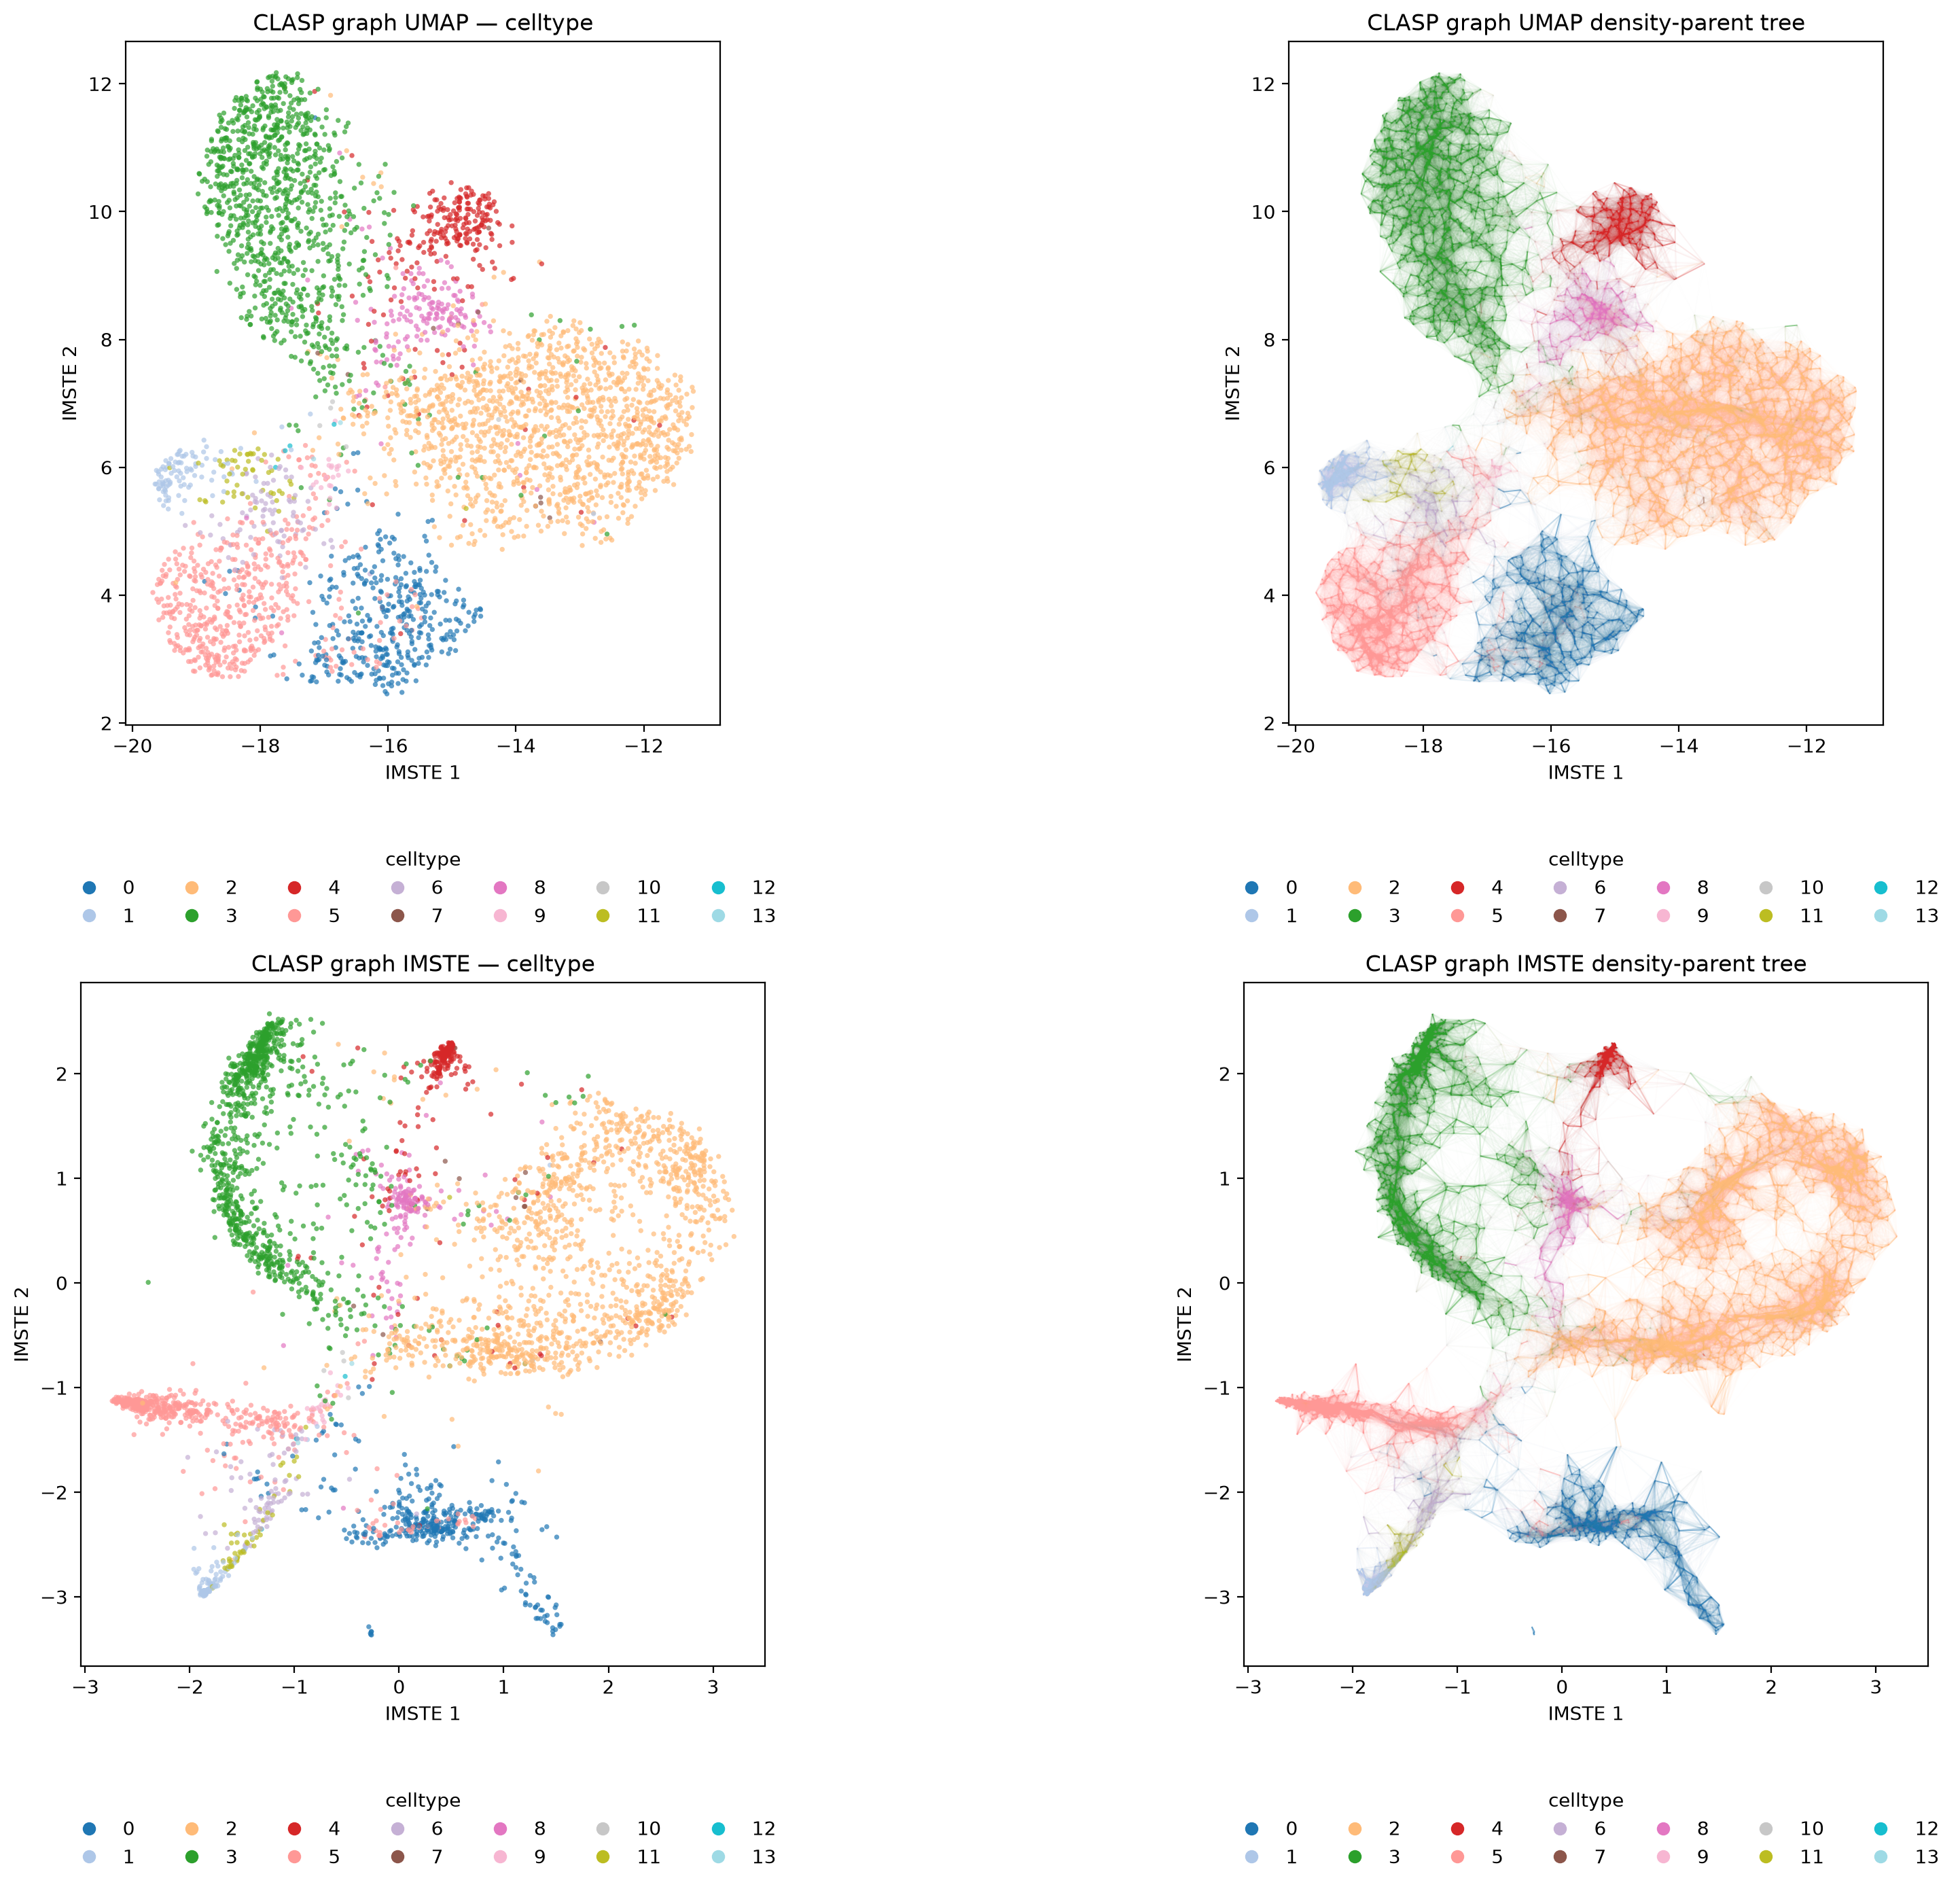

In [6]:
NEIGHBORHOOD_VIEW = NEIGHBORHOOD_VIEW_SELECTOR.value
KNN_VIEW_PARAMS = {
    "k": 7,
    "cv_neighbors": 5,
    "cv_splits": 5,
    "random_state": RANDOM_STATE,
    "distance_std_threshold": 1.0,
    "alpha_range": (0.2, 0.8),
    "legend_position": "bottom",
}

fig, axes = plt.subplots(2, 2, figsize=(18, 14))
plot_embedding(
    umap_embedding, obs, color_keys=(LABEL_KEY,), point_size=7,
    point_alpha=0.7, ax=axes[0, 0], legend_position="bottom",
    label_colors=LABEL_COLORS,
)
axes[0, 0].set_title(f"CLASP graph UMAP — {LABEL_KEY}")
if NEIGHBORHOOD_VIEW == "knn":
    plot_knn_union(
        umap_embedding, obs, label_key=LABEL_KEY, ax=axes[0, 1], **KNN_VIEW_PARAMS
    )
    axes[0, 1].set_title("CLASP graph UMAP kNN neighborhood union")
else:
    plot_density_parent_tree(
        umap_embedding, obs, label_key=LABEL_KEY, point_size=7,
        point_alpha=0.0, edge_alpha=0.5, cross_label_edge_alpha=0.1,
        edge_alpha_exponent=1.2, edge_length_std_threshold=0.85, k=40,
        ax=axes[0, 1], legend_position="bottom", label_colors=LABEL_COLORS,
    )
    axes[0, 1].set_title("CLASP graph UMAP density-parent tree")
plot_embedding(
    imste_embedding, obs, color_keys=(LABEL_KEY,), point_size=7,
    point_alpha=0.7, ax=axes[1, 0], legend_position="bottom",
    label_colors=LABEL_COLORS,
)
axes[1, 0].set_title(f"CLASP graph IMSTE — {LABEL_KEY}")
if NEIGHBORHOOD_VIEW == "knn":
    plot_knn_union(
        imste_embedding, obs, label_key=LABEL_KEY, ax=axes[1, 1], **KNN_VIEW_PARAMS
    )
    axes[1, 1].set_title("CLASP graph IMSTE kNN neighborhood union")
else:
    plot_density_parent_tree(
        imste_embedding, obs, label_key=LABEL_KEY, point_size=7,
        point_alpha=0.0, edge_alpha=0.5, cross_label_edge_alpha=0.1,
        edge_alpha_exponent=1.2, edge_length_std_threshold=0.85, k=40,
        ax=axes[1, 1], legend_position="bottom", label_colors=LABEL_COLORS,
    )
    axes[1, 1].set_title("CLASP graph IMSTE density-parent tree")
fig.tight_layout()
plt.show()


In [7]:
# Interactive label-guided adjustment of the IMSTE embedding.
_visualization_spec = importlib.util.spec_from_file_location(
    "imste_visualization_tools", IMSTE_VISUALIZATION_PATH
)
_interactive_visualization = importlib.util.module_from_spec(_visualization_spec)
_visualization_spec.loader.exec_module(_interactive_visualization)
interactive_force = _interactive_visualization.interactive_force
interactive_force(
    imste_embedding,
    obs,
    label_key=LABEL_KEY,
    initial_k=50,
    initial_iterations=200,
    initial_distance_fraction=0.05,
    max_k=50,
    max_iterations=200,
    label_colors=LABEL_COLORS,
)
